In [4]:

from heapq import nlargest

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics.pairwise import cosine_similarity
from transformers import AutoModelForCausalLM, AutoTokenizer



In [5]:
checkpoint = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(checkpoint)
model = AutoModelForCausalLM.from_pretrained(checkpoint, low_cpu_mem_usage=True)
model.eval()



Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [6]:
embedding_layer = model.get_input_embeddings()
emb = embedding_layer.weight.detach().numpy().astype(np.float64)
print("Embedding matrix shape:", emb.shape)   # (50257, 768)


SQUARE_FIGSIZE = 6

Embedding matrix shape: (50257, 768)


In [7]:
# 
encoded = tokenizer.encode("Hello")
print("Token ID:", encoded)          # [15496]
print("Decoded:", tokenizer.decode(encoded))

# 
encoded = tokenizer.encode("Hello world!")
print("Token IDs:", encoded)         # [15496, 995, 0]
print("First token:", tokenizer.decode(encoded[0]))
print("Last token:", tokenizer.decode(encoded[-1]))

# 
encoded = tokenizer.encode("programmatic")
print("Subword tokens:", encoded)    # [15385, 1070] -> "program" + "matic"

# 
text = "large language models use subword tokenization"
encoded = tokenizer.encode(text)
print("Number of tokens:", len(encoded))   # 8

# 
for number in encoded:
    decoded = tokenizer.decode(number)
    print(f"{number:>6} --> {repr(decoded)}")

Token ID: [15496]
Decoded: Hello
Token IDs: [15496, 995, 0]
First token: Hello
Last token: !
Subword tokens: [23065, 13849]
Number of tokens: 8
 11664 --> 'large'
  3303 --> ' language'
  4981 --> ' models'
   779 --> ' use'
   850 --> ' sub'
  4775 --> 'word'
 11241 --> ' token'
  1634 --> 'ization'


In [8]:
assert emb.shape[0] == model.config.vocab_size

vector = emb[0]
print("Vector length:", len(vector))   # 768

encoded = tokenizer.encode("Hello world!")
for number in encoded:
    vector = emb[number]
    print(f"Token ID {number} -> vector length {len(vector)}")

emb_seq = emb[encoded]
print("Sequence embeddings shape:", emb_seq.shape)   # (3, 768)

Vector length: 768
Token ID 15496 -> vector length 768
Token ID 995 -> vector length 768
Token ID 0 -> vector length 768
Sequence embeddings shape: (3, 768)


In [9]:
A = emb[0]
B = emb[1]

magnitude = np.linalg.norm(A)
print("Magnitude of A:", round(magnitude, 2))

direction = A / magnitude
print("Direction vector length:", len(direction))
print("Magnitude of direction:", round(np.linalg.norm(direction), 2))   # 1.0

Magnitude of A: 3.07
Direction vector length: 768
Magnitude of direction: 1.0


In [10]:
# 
dot = np.dot(A, B)   
print("Dot product:", round(dot, 2))

# 
cos_sim = dot / (np.linalg.norm(A) * np.linalg.norm(B))
print("Cosine similarity:", round(cos_sim, 2))

# 
sim_matrix = cosine_similarity([A, B])   # 2x2 
print("Similarity matrix:\n", np.round(sim_matrix, 3))

Dot product: 4.23
Cosine similarity: 0.45
Similarity matrix:
 [[1.    0.447]
 [0.447 1.   ]]


In [11]:
# 
query_enc = tokenizer.encode(" language")
query_vec = emb[query_enc]   # 

#
scores = cosine_similarity(query_vec, emb)[0]   # 

# 
top_k = 25
scored = [(scores[i], i) for i in range(len(scores))]
top = nlargest(top_k, scored)

print("Top 25 tokens most similar to 'language':")
for score, idx in top:
    token = tokenizer.decode(idx)
    print(f"{repr(token):<15} {score:.3f}")

Top 25 tokens most similar to 'language':
' language'     1.000
' Language'     0.804
' languages'    0.698
'language'      0.659
'Language'      0.642
' linguistic'   0.576
' Languages'    0.565
' vocabulary'   0.530
' dialect'      0.509
' terminology'  0.502
' rhetoric'     0.494
' words'        0.494
' grammar'      0.483
'anguages'      0.480
' syntax'       0.479
'anguage'       0.477
' wording'      0.467
' phrase'       0.460
' jargon'       0.455
' phrases'      0.453
' lang'         0.451
' speak'        0.447
' word'         0.446
'speaking'      0.445
' lingu'        0.438


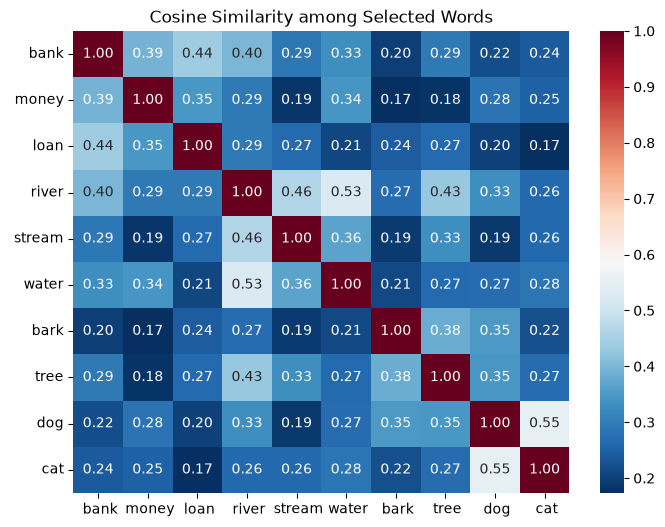

In [12]:
words = " bank money loan river stream water bark tree dog cat"
encoded = tokenizer.encode(words)
batch_emb = emb[encoded]   # (10, 768)

# 
sim = cosine_similarity(batch_emb)   # (10, 10)

# 
labels = [tokenizer.decode(tok) for tok in encoded]

# 
fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(sim, annot=True, fmt=".2f", cmap="RdBu_r",
            xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_title("Cosine Similarity among Selected Words")
plt.show()

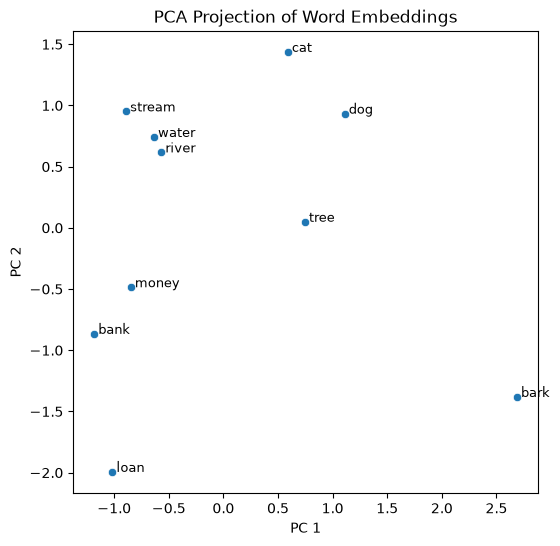

In [13]:
# 
pca = PCA(n_components=2)
emb_2d = pca.fit_transform(batch_emb)

# 
fig, ax = plt.subplots(figsize=(SQUARE_FIGSIZE, SQUARE_FIGSIZE))
sns.scatterplot(x=emb_2d[:, 0], y=emb_2d[:, 1], ax=ax)
for i, label in enumerate(labels):
    ax.text(emb_2d[i, 0], emb_2d[i, 1], label, fontsize=9)
ax.set_title("PCA Projection of Word Embeddings")
ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
plt.show()